In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, sys
ROOT = '/content/drive/MyDrive/DSP_Deconv'
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['lib', 'data', 'results', 'figures', 'configs', '04_real_data.ipynb', '00_setup_data.ipynb', '05_figures_new.ipynb', '01_forward_baselines_new.ipynb', '03_experiments_new.ipynb', '02_proposed_new.ipynb', '04_real_data_new.ipynb']


In [ ]:
!pip -q install scikit-image tifffile pyyaml

import sys
import importlib
try:
    import imp
except ModuleNotFoundError:
    import types
    imp = types.ModuleType('imp')
    imp.reload = importlib.reload
    sys.modules['imp'] = imp

%load_ext autoreload
%autoreload 2
import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
numpy 2.1.3 | scipy 1.16.3 | skimage 0.25.2


In [ ]:
import yaml
cfg = yaml.safe_load(open(f'{ROOT}/configs/params.yaml'))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

In [ ]:
import os, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from forward import *; from data import *; from baselines import *; from proposed import *; from metrics import *
tuned = yaml.safe_load(open(f'{ROOT}/configs/tuned.yaml'))
RES, FIG, TAB = f'{ROOT}/results', f'{ROOT}/figures', f'{ROOT}/results/tables'
os.makedirs(TAB, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10})
ORDER = ['wiener_const', 'tikhonov_gcv', 'rl', 'unsup_wiener', 'proposed', 'oracle_wiener']
COLOR = {m: f'C{i}' for i, m in enumerate(ORDER)}

gt, _ = fmd_pair('WideField_BPAE_B', 1)          
x_dev = center_crop(norm_pair(gt)[0], cfg['crop'])

def mean_std(d, keys, col, nd=2, order=ORDER):
    """'mean ± std' strings, one column per method."""
    g = d.groupby(keys + ['method'])[col]
    t = (g.mean().round(nd).astype(str) + ' ± ' + g.std().round(nd).astype(str)).unstack()
    return t[[m for m in order if m in t.columns]]

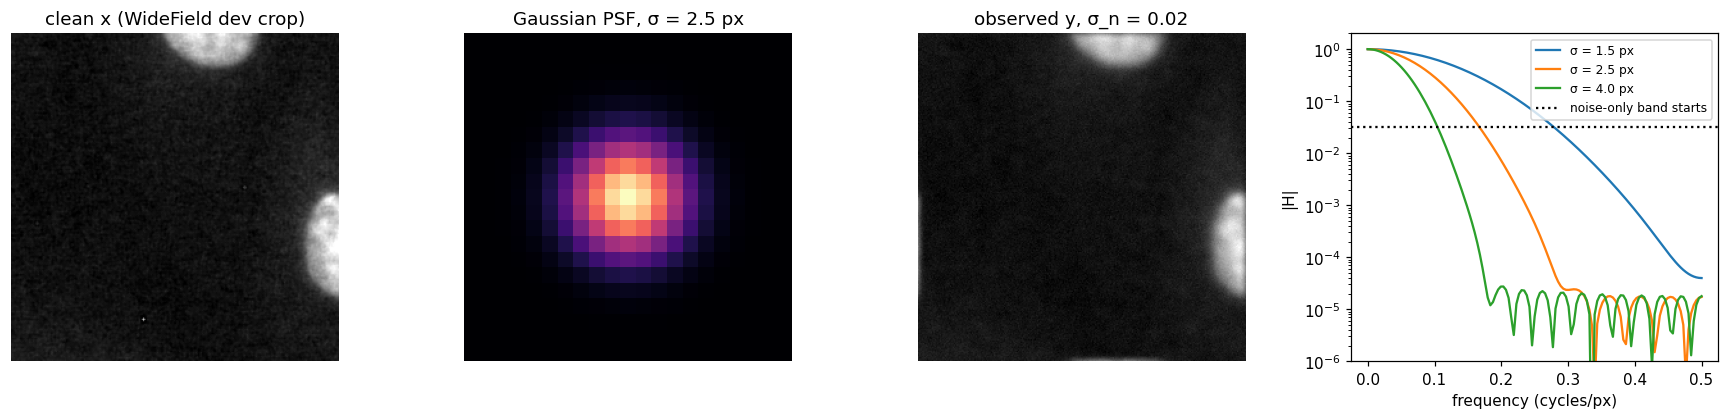

In [ ]:
psf = gaussian_psf(psf_size(2.5), 2.5)
y = add_gaussian(blur(x_dev, psf), 0.02, np.random.default_rng(0))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
ax[0].imshow(x_dev, cmap='gray'); ax[0].set_title('clean x (WideField dev crop)')
ax[1].imshow(psf, cmap='magma'); ax[1].set_title('Gaussian PSF, σ = 2.5 px')
ax[2].imshow(np.clip(y, 0, 1), cmap='gray'); ax[2].set_title('observed y, σ_n = 0.02')
for a in ax[:3]: a.axis('off')
f = np.fft.rfftfreq(cfg['crop'])
for s in cfg['psf_sigmas']:
    H = np.abs(psf2otf(gaussian_psf(psf_size(s), s), (cfg['crop'], cfg['crop'])))[0, :len(f)]
    ax[3].semilogy(f, H, label=f'σ = {s} px')
ax[3].axhline(np.sqrt(cfg['eps_band']), ls=':', c='k', label='noise-only band starts')
ax[3].set_xlabel('frequency (cycles/px)'); ax[3].set_ylabel('|H|'); ax[3].set_ylim(1e-6, 2); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig1_forward_model.png'); plt.show()

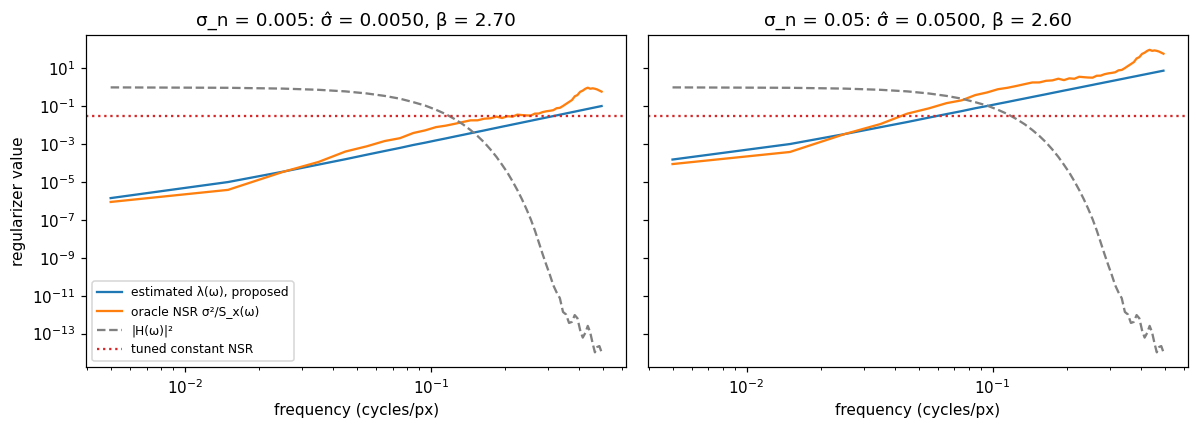

In [ ]:
w = freq_grid(x_dev.shape); bins = np.linspace(0, 0.5, 51); fc = (bins[:-1] + bins[1:]) / 2
radial = lambda M: np.array([np.median(M[(w >= a) & (w < b)]) for a, b in zip(bins[:-1], bins[1:])])
psf = gaussian_psf(psf_size(2.5), 2.5)
H2 = np.abs(psf2otf(psf, x_dev.shape)) ** 2
Sx = np.abs(np.fft.fft2(x_dev)) ** 2 / x_dev.size
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, s_n in zip(ax, [0.005, 0.05]):
    y = add_gaussian(blur(x_dev, psf), s_n, np.random.default_rng(0))
    _, info = adaptive_wiener(y, psf, return_info=True)
    a.loglog(fc, radial(info['lam']), label='estimated λ(ω), proposed')
    a.loglog(fc, radial(s_n ** 2 / (Sx + 1e-12)), label='oracle NSR σ²/S_x(ω)')
    a.loglog(fc, radial(H2), '--', c='gray', label='|H(ω)|²')
    a.axhline(tuned['nsr'], c='C3', ls=':', label='tuned constant NSR')
    a.set_title(f'σ_n = {s_n}: σ̂ = {np.sqrt(info["sigma2"]):.4f}, β = {info["beta"]:.2f}')
    a.set_xlabel('frequency (cycles/px)')
ax[0].set_ylabel('regularizer value'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig2_lambda.png'); plt.show()

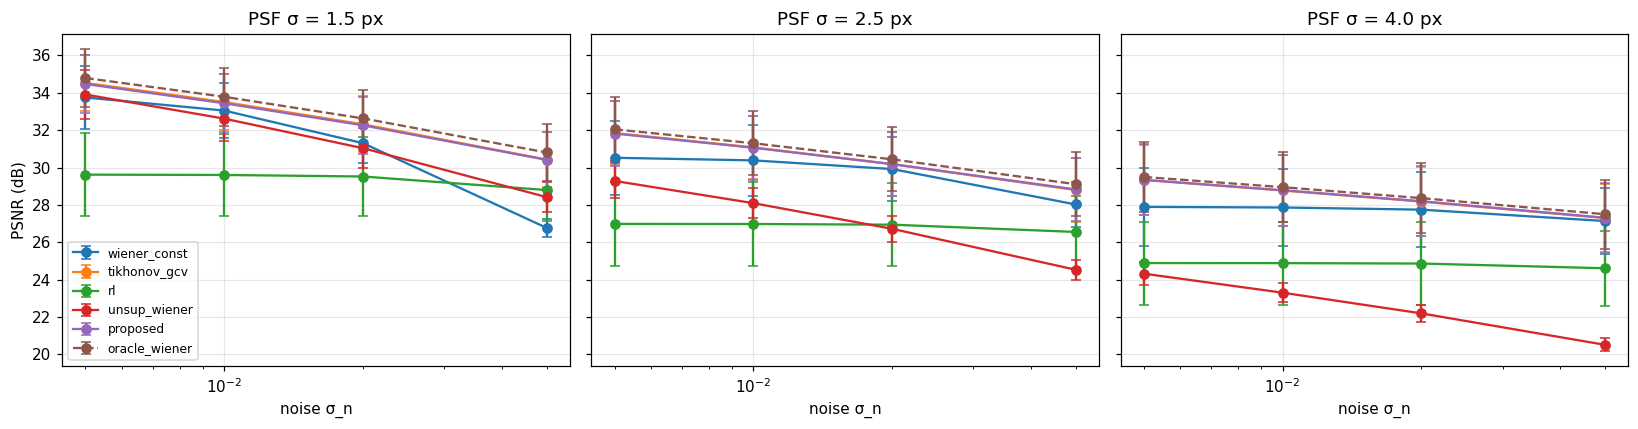

method     wiener_const  tikhonov_gcv            rl  unsup_wiener  \
psf noise                                                           
1.5 0.005  33.75 ± 1.69  34.53 ± 1.51  29.62 ± 2.22  33.91 ± 1.32   
    0.010  33.05 ± 1.46  33.51 ± 1.52    29.6 ± 2.2  32.62 ± 1.21   
    0.020   31.3 ± 1.06  32.32 ± 1.49  29.52 ± 2.14  31.03 ± 1.06   
    0.050  26.77 ± 0.48   30.43 ± 1.5  28.79 ± 1.65   28.42 ± 0.8   
2.5 0.005  30.52 ± 1.98  31.85 ± 1.69  26.98 ± 2.25  29.28 ± 0.94   
    0.010  30.38 ± 1.91   31.08 ± 1.7  26.97 ± 2.24   28.09 ± 0.8   
    0.020  29.92 ± 1.73  30.18 ± 1.71  26.94 ± 2.21  26.72 ± 0.69   
    0.050  28.02 ± 1.19  28.79 ± 1.71  26.55 ± 1.92  24.52 ± 0.54   
4.0 0.005  27.89 ± 2.09  29.33 ± 1.89  24.88 ± 2.22  24.32 ± 0.61   
    0.010  27.86 ± 2.07  28.77 ± 1.88  24.88 ± 2.22   23.3 ± 0.52   
    0.020  27.74 ± 2.01  28.17 ± 1.87   24.86 ± 2.2  22.19 ± 0.45   
    0.050  27.13 ± 1.75  27.29 ± 1.83  24.61 ± 2.02   20.5 ± 0.34   

method         proposed oracle_wiener  
psf noise                              
1.5 0.005  34.47 ± 1.53  34.79 ± 1.54  
    0.010  33.44 ± 1.55  33.79 ± 1.55  
    0.020  32.26 ± 1.54  32.63 ± 1.54  
    0.050  30.41 ± 1.51   30.8 ± 1.51  
2.5 0.005  31.82 ± 1.72  32.04 ± 1.72  
    0.010  31.06 ± 1.71   31.3 ± 1.71  
    0.020  30.18 ± 1.72  30.44 ± 1.71  
    0.050  28.83 ± 1.71   29.11 ± 1.7  
4.0 0.005   29.34 ± 1.9  29.49 ± 1.89  
    0.010  28.78 ± 1.89  28.95 ± 1.89  
    0.020  28.19 ± 1.88  28.36 ± 1.88  
    0.050  27.31 ± 1.86   27.5 ± 1.86

In [ ]:
df = pd.read_csv(f'{RES}/synthetic_gauss_test.csv'); df = df[df.method != 'inverse']
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, s in zip(ax, cfg['psf_sigmas']):
    d = df[df.psf == s].groupby(['method', 'noise']).psnr.agg(['mean', 'std']).reset_index()
    for m in ORDER:
        r = d[d.method == m]
        a.errorbar(r.noise, r['mean'], yerr=r['std'], marker='o', capsize=3, color=COLOR[m], label=m,
                   ls='--' if m == 'oracle_wiener' else '-')
    a.set_xscale('log'); a.set_title(f'PSF σ = {s} px'); a.set_xlabel('noise σ_n'); a.grid(alpha=0.3)
ax[0].set_ylabel('PSNR (dB)'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig3_psnr_vs_noise.png'); plt.show()

mean_std(df, ['psf', 'noise'], 'psnr').to_csv(f'{TAB}/table1_gauss_psnr.csv')
mean_std(df, ['psf', 'noise'], 'ssim', 3).to_csv(f'{TAB}/table1b_gauss_ssim.csv')
df.groupby('method')[['psnr', 'ssim', 'lsd', 'ms']].agg(['mean', 'std']).round(3).to_csv(f'{TAB}/table2_overall.csv')
mean_std(df, ['psf', 'noise'], 'psnr')

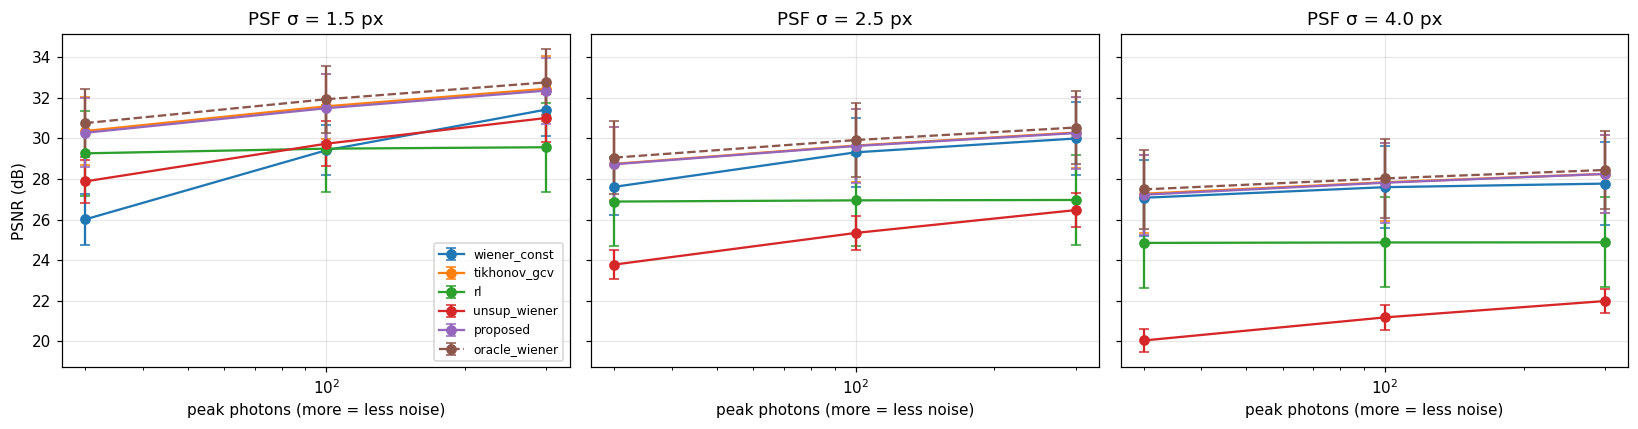

In [ ]:
p = Path(f'{RES}/synthetic_pg_test.csv')
if p.exists():
    pg = pd.read_csv(p)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for a, s in zip(ax, cfg['psf_sigmas']):
        d = pg[pg.psf == s].groupby(['method', 'peak']).psnr.agg(['mean', 'std']).reset_index()
        for m in ORDER:
            r = d[d.method == m]
            a.errorbar(r.peak, r['mean'], yerr=r['std'], marker='o', capsize=3, color=COLOR[m], label=m,
                       ls='--' if m == 'oracle_wiener' else '-')
        a.set_xscale('log'); a.set_title(f'PSF σ = {s} px'); a.set_xlabel('peak photons (more = less noise)'); a.grid(alpha=0.3)
    ax[0].set_ylabel('PSNR (dB)'); ax[0].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f'{FIG}/fig3b_psnr_poisson.png'); plt.show()
    mean_std(pg, ['psf', 'peak'], 'psnr').to_csv(f'{TAB}/table3_pg_psnr.csv')
else:
    print('synthetic_pg_test.csv not found: run 03_experiments S6 Cell B2 first')

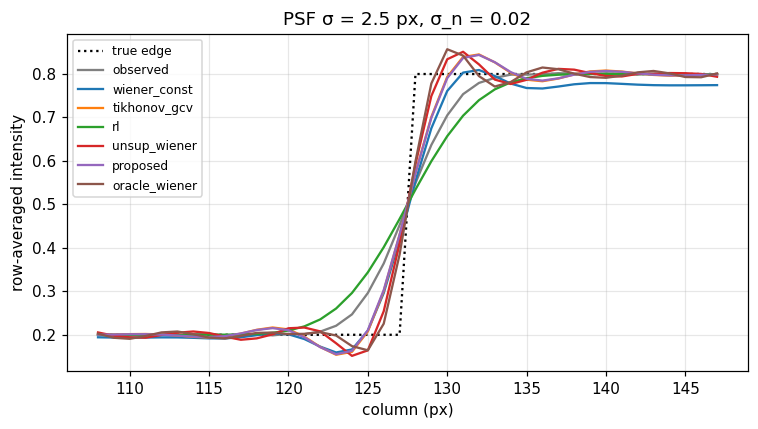

fwhm_px         mtf50        overshoot_pct        noise_amp  \
                 mean    std   mean    std          mean    std      mean   
method                                                                      
oracle_wiener   3.176  0.294  0.190  0.018         9.382  1.532     0.636   
proposed        4.813  0.777  0.127  0.021         7.374  0.843     0.879   
rl              8.359  0.020  0.055  0.000         0.103  0.102     0.448   
tikhonov_gcv    4.804  0.797  0.127  0.021         7.582  0.711     0.888   
unsup_wiener    3.716  0.358  0.163  0.013         8.217  0.724     3.421   
wiener_const    4.806  0.057  0.121  0.002         1.312  0.371     0.620   

                      
                 std  
method                
oracle_wiener  0.493  
proposed       0.536  
rl             0.306  
tikhonov_gcv   0.551  
unsup_wiener   1.826  
wiener_const   0.015

In [ ]:
x = edge_phantom(); psf = gaussian_psf(psf_size(2.5), 2.5); s_n = 0.02
y = add_gaussian(blur(x, psf), s_n, np.random.default_rng(0))
outs = {'observed': y,
        'wiener_const': wiener_const(y, psf, tuned['nsr']),
        'tikhonov_gcv': tikhonov_gcv(y, psf),
        'rl': rl(y, psf, tuned['rl_iter']),
        'unsup_wiener': unsup_wiener(y, psf),
        'proposed': adaptive_wiener(y, psf),
        'oracle_wiener': wiener_oracle(y, psf, x, s_n)}
n = x.shape[1]; cols = np.arange(n // 2 - 20, n // 2 + 20)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cols, x[:, cols].mean(0), 'k:', label='true edge')
for m, im in outs.items():
    ax.plot(cols, im[:, cols].mean(0), color=COLOR.get(m, 'gray'), label=m)
ax.set_xlabel('column (px)'); ax.set_ylabel('row-averaged intensity'); ax.set_title(f'PSF σ = 2.5 px, σ_n = {s_n}')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG}/fig4_edge_profiles.png'); plt.show()

e = pd.read_csv(f'{RES}/edge_test.csv')
t4 = e.groupby('method')[['fwhm_px', 'mtf50', 'overshoot_pct', 'noise_amp']].agg(['mean', 'std']).round(3)
t4.to_csv(f'{TAB}/table4_edge.csv')
e.groupby(['noise', 'method'])[['fwhm_px', 'mtf50', 'overshoot_pct', 'noise_amp']].mean().round(3).to_csv(f'{TAB}/table4b_edge_by_noise.csv')
t4

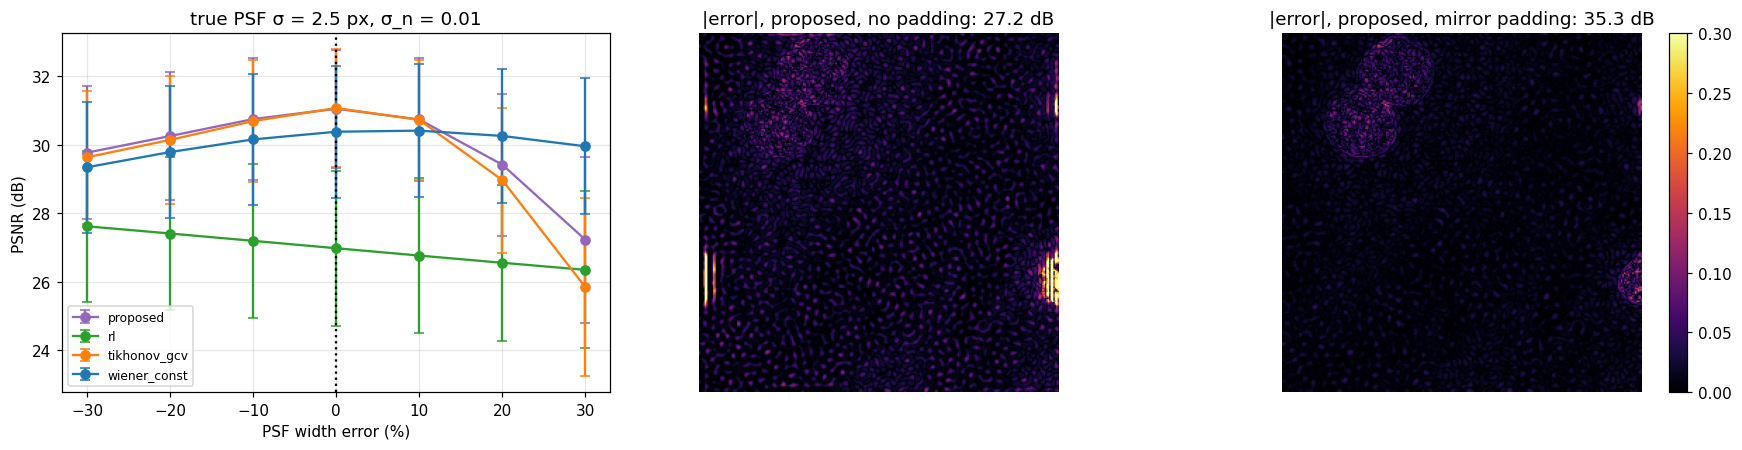

psnr_plain       psnr_padded      
                   mean   std        mean   std
method                                         
proposed          25.95  2.86       28.58  3.43
tikhonov_gcv      14.41  8.75       17.48  9.00
wiener_const      30.24  1.98       30.91  2.39

In [ ]:
mis = pd.read_csv(f'{RES}/psf_mismatch.csv'); bnd = pd.read_csv(f'{RES}/boundary.csv')
psf = gaussian_psf(psf_size(2.5), 2.5)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
d = mis.groupby(['method', 'error_pct']).psnr.agg(['mean', 'std']).reset_index()
for m in d.method.unique():
    r = d[d.method == m]
    ax[0].errorbar(r.error_pct, r['mean'], yerr=r['std'], marker='o', capsize=3, color=COLOR[m], label=m)
ax[0].axvline(0, c='k', ls=':'); ax[0].set_xlabel('PSF width error (%)'); ax[0].set_ylabel('PSNR (dB)')
ax[0].set_title('true PSF σ = 2.5 px, σ_n = 0.01'); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

x = quadrants(norm_pair(fmd_pair('Confocal_BPAE_B', 19)[0])[0])[0]
y = add_gaussian(blur(x, psf, boundary='reflect'), 0.01, np.random.default_rng(0))
for a, (title, xh) in zip(ax[1:], [('no padding', adaptive_wiener(y, psf)), ('mirror padding', padded(adaptive_wiener, y, psf))]):
    xc = np.clip(xh, 0, 1)
    im = a.imshow(np.abs(xc - x), cmap='inferno', vmin=0, vmax=0.3)
    a.set_title(f'|error|, proposed, {title}: {psnr(x, xc):.1f} dB'); a.axis('off')
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.savefig(f'{FIG}/fig5_robustness.png'); plt.show()

d.pivot_table(index='error_pct', columns='method', values='mean').round(2).to_csv(f'{TAB}/table5_psf_mismatch.csv')
t5 = bnd.groupby('method')[['psnr_plain', 'psnr_padded']].agg(['mean', 'std']).round(2)
t5.to_csv(f'{TAB}/table5b_boundary.csv'); t5

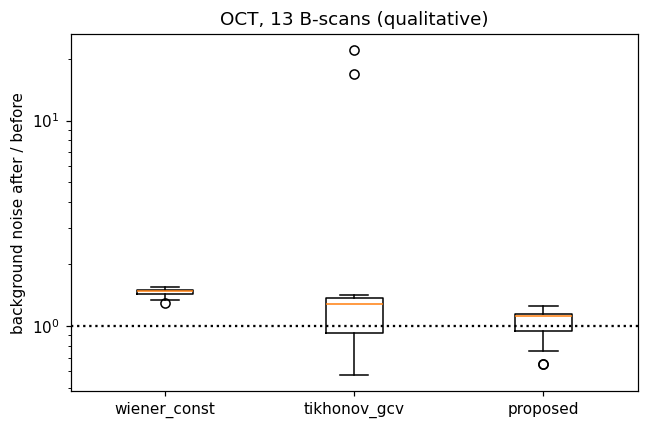

background_noise_ratio                lateral_mtf50              
                               mean    std     max          mean    std    max
method                                                                        
proposed                      1.020  0.205   1.252         0.179  0.014  0.192
tikhonov_gcv                  3.897  6.957  21.970         0.204  0.064  0.348
wiener_const                  1.453  0.079   1.543         0.212  0.000  0.212

In [ ]:
fmd = pd.read_csv(f'{RES}/real_fmd.csv'); oct_df = pd.read_csv(f'{RES}/real_oct.csv')
fmd.pivot_table(index=['subset', 'psf'], columns='method', values=['noise_gain', 'mtf50']).round(3).to_csv(f'{TAB}/table6_real_fmd.csv')
oct_df.groupby('method')[['background_noise_ratio', 'lateral_mtf50']].agg(['mean', 'std', 'max']).round(3).to_csv(f'{TAB}/table7_real_oct.csv')

methods = ['wiener_const', 'tikhonov_gcv', 'proposed']
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([oct_df[oct_df.method == m].background_noise_ratio for m in methods])
ax.set_xticks(range(1, len(methods) + 1), methods)
ax.axhline(1, c='k', ls=':'); ax.set_yscale('log')
ax.set_ylabel('background noise after / before'); ax.set_title(f'OCT, {oct_df.image.nunique()} B-scans (qualitative)')
plt.tight_layout(); plt.savefig(f'{FIG}/fig6_oct_noise.png'); plt.show()
oct_df.groupby('method')[['background_noise_ratio', 'lateral_mtf50']].agg(['mean', 'std', 'max']).round(3)

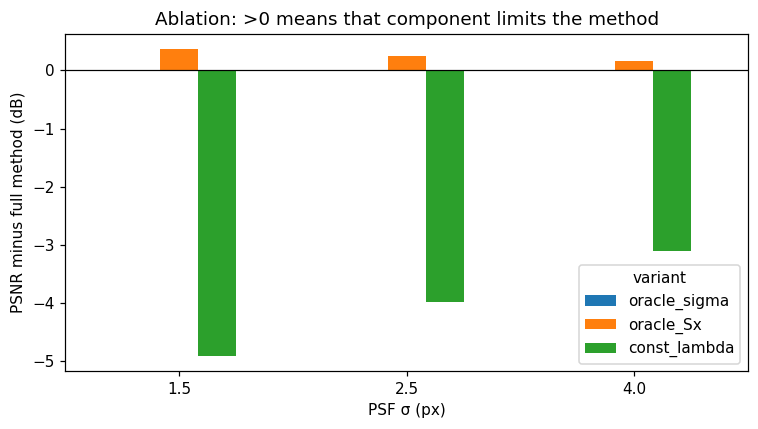

variant oracle_sigma      oracle_Sx       const_lambda      
                mean  std      mean   std         mean   std
psf                                                         
1.5              0.0  0.0      0.36  0.07        -4.91  4.66
2.5              0.0  0.0      0.25  0.05        -3.98  4.00
4.0             -0.0  0.0      0.17  0.03        -3.10  3.29

In [ ]:
abl = pd.read_csv(f'{RES}/ablation.csv')
p = abl.pivot_table(index=['img', 'psf', 'noise', 'seed'], columns='variant', values='psnr')
gain = p[['oracle_sigma', 'oracle_Sx', 'const_lambda']].sub(p['full'], axis=0)
t8 = gain.groupby(level='psf').agg(['mean', 'std']).round(2)
t8.to_csv(f'{TAB}/table8_ablation.csv')
gain.groupby(level='psf').mean().plot.bar(figsize=(7, 4), rot=0)
plt.axhline(0, c='k', lw=0.8); plt.ylabel('PSNR minus full method (dB)'); plt.xlabel('PSF σ (px)')
plt.title('Ablation: >0 means that component limits the method')
plt.tight_layout(); plt.savefig(f'{FIG}/fig7_ablation.png'); plt.show()

full = abl[abl.variant == 'full']
full.groupby(['psf', 'noise'])[['sigma_ratio', 'beta']].agg(['mean', 'std']).round(3).to_csv(f'{TAB}/table9_estimator_accuracy.csv')
t8

In [ ]:
print(pd.read_csv(f'{RES}/wilcoxon.csv').round(4).to_string(index=False))
print(sorted(os.listdir(FIG))); print(sorted(os.listdir(TAB)))

     noise_model     baseline   n  median_gain_db  mean_gain_db  frac_proposed_wins  p_value
        gaussian wiener_const 480          0.7159        0.9792              1.0000   0.0000
        gaussian tikhonov_gcv 480          0.0041       -0.0128              0.5438   0.0469
        gaussian           rl 480          3.4989        3.4911              1.0000   0.0000
        gaussian unsup_wiener 480          3.1364        3.4332              1.0000   0.0000
poisson_gaussian wiener_const 360          0.4708        1.0905              0.9833   0.0000
poisson_gaussian tikhonov_gcv 360         -0.0152       -0.0457              0.3194   0.0000
poisson_gaussian           rl 360          2.6374        2.4790              1.0000   0.0000
poisson_gaussian unsup_wiener 360          4.2009        4.2907              1.0000   0.0000
['boundary_error_map.png', 'fig1_forward_model.png', 'fig2_lambda.png', 'fig3_psnr_vs_noise.png', 'fig3b_psnr_poisson.png', 'fig4_edge_profiles.png', 'fig5_robustn